# Prédiction de la demande de vélos à Séoul : introduction

Ce notebook présente le projet : le sujet, la problématique, les données et leur preprocessing, les deux protocoles d'évaluation et les algorithmes testés. Tout ce qui est ici est commun à tous les modèles.

## 1. Le sujet

Séoul dispose d'un service de vélos en libre-service. Pour que les usagers trouvent toujours un vélo disponible, l'opérateur doit **anticiper la demande** : combien de vélos seront loués à chaque heure ?

Le dataset *Seoul Bike Sharing Demand* (UCI) contient **une ligne par heure** du 1er décembre 2017 au 30 novembre 2018, avec :
- la **cible** : `rented_bike_count`, le nombre de vélos loués pendant l'heure ;
- la **météo** : température, humidité, vent, visibilité, ensoleillement, pluie, neige ;
- le **calendrier** : heure, jour, mois, saison, week-end, jour férié.

C'est un problème de **régression** : on prédit un nombre

### Problématique

> **À partir de la météo et du calendrier, peut-on prédire le nombre de vélos loués à chaque heure ?**

On répond avec deux approches, qui mesurent deux façons de généraliser :
1. **Généraliser à une journée jamais vue** (protocole **daily**) : le modèle doit prédire des journées entières, tirées au hasard dans l'année, qu'il n'a pas vues à l'entraînement. Les jours autour sont connus et toutes les saisons sont représentées. On mesure si le modèle a bien appris le lien entre la demande, la météo et le calendrier.
2. **Généraliser au futur** (protocole **temporal**) : le modèle apprend uniquement sur le passé et doit prédire les semaines suivantes, comme l'opérateur en conditions réelles. On mesure si ce qu'il a appris reste valable dans le temps, en particulier quand la saison change.

Pour chaque modèle, on compare les deux approches : un modèle peut être très bon sur une journée inconnue et nettement moins bon sur le futur.

## 2. Les données brutes

Le preprocessing est codé dans `decoupage.py` (fonctions `charger_brut` et `preprocessing`) et utilisé par tous les notebooks via `charger_donnees()`. Ici on regarde les données et on justifie chaque choix.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from decoupage import (charger_brut, charger_donnees, decoupage_daily, cv_daily, decoupage_temporal, cv_temporal,
                       variables, VARIABLES_BORNEES, CIBLE)

brut = charger_brut()
print(f"{brut.shape[0]} lignes, {brut.shape[1]} colonnes, du {brut['date'].min():%d/%m/%Y} au {brut['date'].max():%d/%m/%Y}")
print(f"Valeurs manquantes : {brut.isna().sum().sum()} | Doublons : {brut.duplicated().sum()}")
brut.head()

8760 lignes, 14 colonnes, du 01/12/2017 au 30/11/2018
Valeurs manquantes : 0 | Doublons : 0


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,season,holiday,functioning_day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


8 760 lignes : une par heure pendant 365 jours, sans valeur manquante ni doublon. Il y a 14 colonnes : la date, la cible, l'heure, 8 variables météo et 3 colonnes texte (`season`, `holiday`, `functioning_day`) qu'il faudra transformer en nombres.

### La demande jour par jour

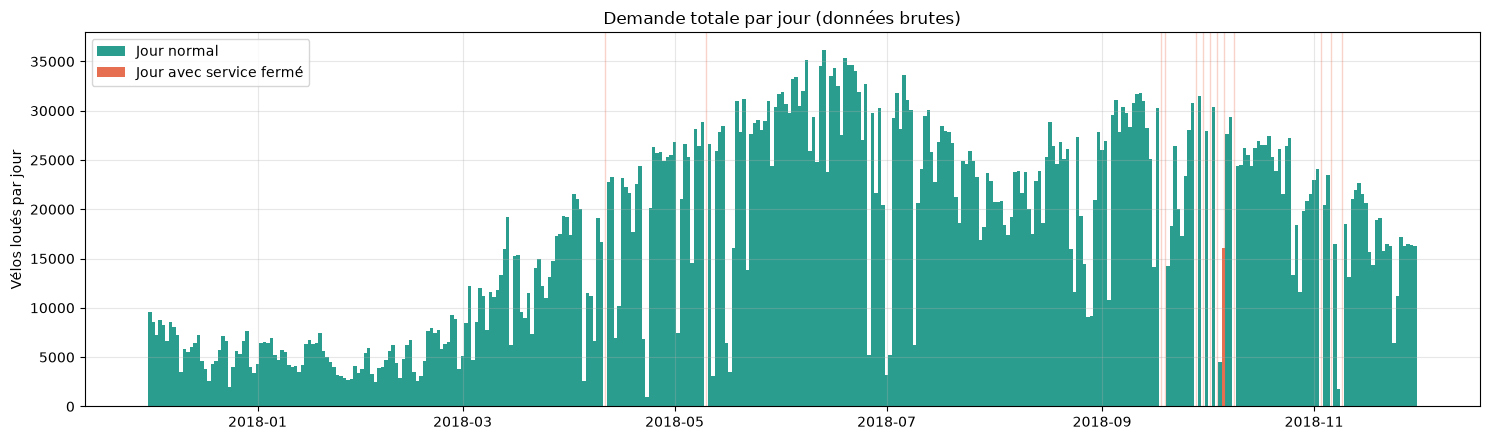

Jours avec service fermé : 13, dont 11 entre septembre et novembre


In [2]:
par_jour = brut.groupby("date").agg(demande=(CIBLE, "sum"), ferme=("functioning_day", lambda s: (s == "No").any()))

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.bar(par_jour.index[~par_jour["ferme"]], par_jour.loc[~par_jour["ferme"], "demande"], width=1, color="#2a9d8f", label="Jour normal")
ax.bar(par_jour.index[par_jour["ferme"]], par_jour.loc[par_jour["ferme"], "demande"], width=1, color="#e76f51", label="Jour avec service fermé")
for date in par_jour.index[par_jour["ferme"]]:
    ax.axvline(date, color="#e76f51", alpha=0.3, linewidth=1)
ax.set(ylabel="Vélos loués par jour", title="Demande totale par jour (données brutes)")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Jours avec service fermé : {par_jour['ferme'].sum()}, dont {par_jour.loc['2018-09-01':, 'ferme'].sum()} entre septembre et novembre")

- **Une forte saisonnalité** : environ 5 000 vélos par jour en hiver, jusqu'à 30 000 en juin (36 149 le 13/06/2018, record de l'année). La demande remonte à partir de mars et redescend en novembre.
- **De fortes chutes d'un jour à l'autre**, même en été : entre mai et septembre, 10 jours tombent sous 10 000 vélos, et ce sont tous des jours de pluie (de 8 à 96 mm dans la journée). Une journée de forte pluie en été descend au niveau d'une journée d'hiver (voir 3.3).
- **Des jours à 0 ou presque** (traits orange) : ce sont les 13 jours où le service était fermé (voir 3.1). 11 d'entre eux tombent entre le 18/09 et le 09/11, c'est-à-dire dans la période du test temporal.

## 3. Preprocessing

### 3.1 Les heures où le service était fermé

In [3]:
print(brut.groupby("functioning_day")[CIBLE].agg(["count", "mean", "max"]))
print(f"\nJours avec au moins une heure fermée : {brut.loc[brut['functioning_day'] == 'No', 'date'].nunique()}")

ouvert = brut[brut["functioning_day"] == "Yes"]

                 count        mean   max
functioning_day                         
No                 295    0.000000     0
Yes               8465  729.156999  3556

Jours avec au moins une heure fermée : 13


Les 295 heures où `functioning_day = No` ont toutes **0 location** : le service était fermé (12 jours entiers et quelques heures d'un 13e jour). Ce n'est pas une demande nulle, c'est une absence de service : si on les gardait, le modèle apprendrait des zéros qu'il ne peut pas expliquer avec la météo ou le calendrier.

**Choix :** on retire ces 295 heures. La colonne `functioning_day` ne vaut alors plus que « Yes », donc on la supprime aussi. Il reste 8 465 heures sur 353 jours.

**Utilisé dans :** tous les notebooks, via `charger_donnees()`. Dans `decoupage_donnees.ipynb`, une semaine de test compte 7 jours *de service* ; dans `comparaison_finale.ipynb` et `reseau_neurones.ipynb`, ces heures apparaissent comme des trous dans les graphiques de prédiction.

### 3.2 Corrélations entre variables

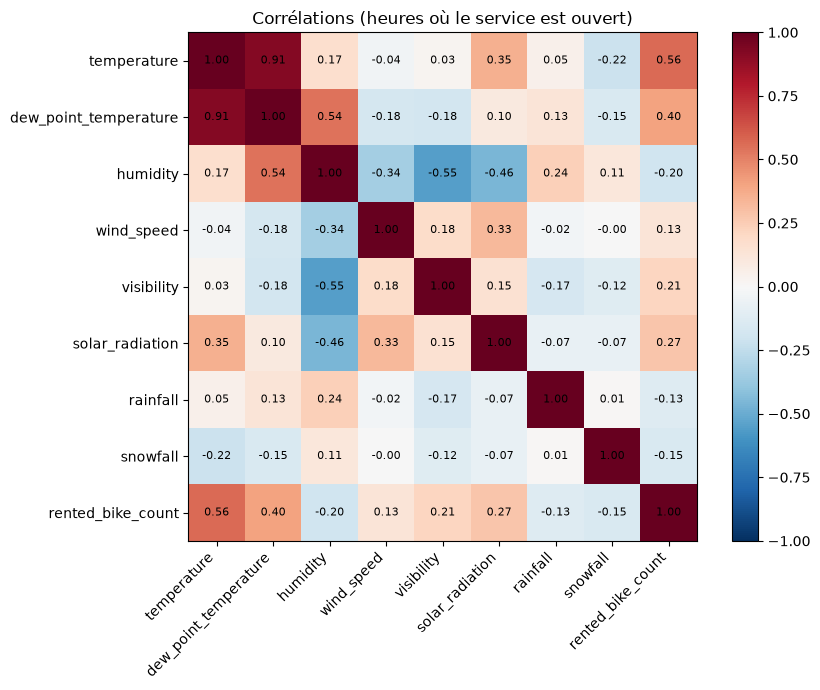

In [4]:
numeriques = ["temperature", "dew_point_temperature", "humidity", "wind_speed", "visibility",
              "solar_radiation", "rainfall", "snowfall", CIBLE]
corr = ouvert[numeriques].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeriques)), numeriques, rotation=45, ha="right")
ax.set_yticks(range(len(numeriques)), numeriques)
for i in range(len(numeriques)):
    for j in range(len(numeriques)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Corrélations (heures où le service est ouvert)")
plt.tight_layout()
plt.show()

- `temperature` et `dew_point_temperature` (température du point de rosée) sont **très corrélées (0,91)** : elles donnent presque la même information.
- La température est la variable météo la plus liée à la demande (0,56), le point de rosée l'est moins (0,40).

**Choix :** on supprime `dew_point_temperature` et on garde `temperature`, la plus liée à la demande. Avec les deux, les poids d'une régression linéaire seraient difficiles à interpréter : l'une pourrait compenser l'autre (un gros poids positif sur l'une, un gros poids négatif sur l'autre).

**Utilisé dans :** `regression_lineaire.ipynb`, section 4 (analyse des poids du modèle 1).

### 3.3 Valeurs extrêmes de la météo

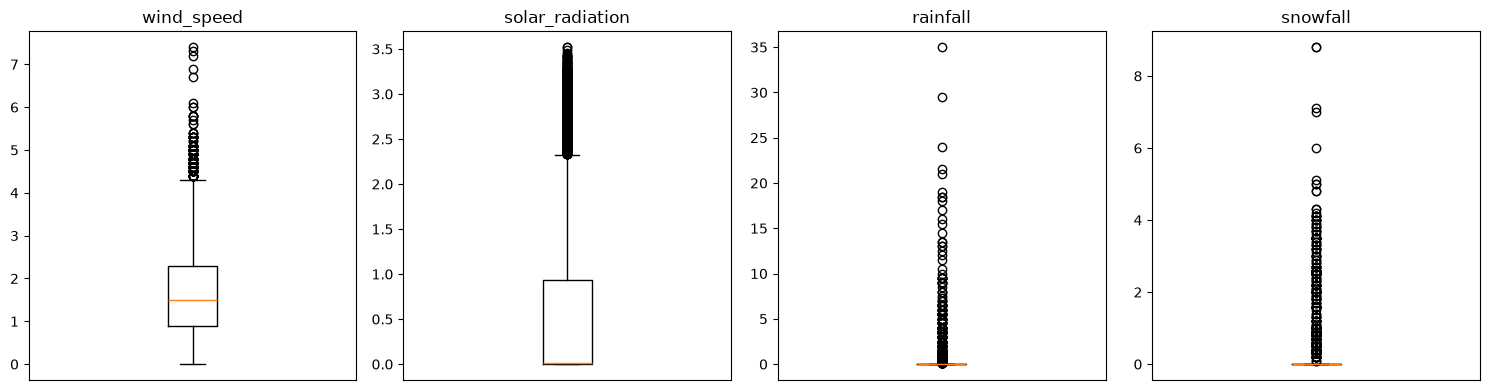

wind_speed       max =  7.40 -> borné à [0.10, 4.70] (145 heures modifiées)
solar_radiation  max =  3.52 -> borné à [0.00, 3.17] (82 heures modifiées)
rainfall         max = 35.00 -> borné à [0.00, 4.00] (76 heures modifiées)
snowfall         max =  8.80 -> borné à [0.00, 2.50] (81 heures modifiées)


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, VARIABLES_BORNEES):
    ax.boxplot(ouvert[col])
    ax.set(title=col, xticks=[])
plt.tight_layout()
plt.show()

for col in VARIABLES_BORNEES:
    bas, haut = ouvert[col].quantile(0.01), ouvert[col].quantile(0.99)
    n = ((ouvert[col] < bas) | (ouvert[col] > haut)).sum()
    print(f"{col:<16} max = {ouvert[col].max():5.2f} -> borné à [{bas:.2f}, {haut:.2f}] ({n} heures modifiées)")

Ces quatre variables ont quelques valeurs très éloignées des autres (jusqu'à 35 mm de pluie en une heure, alors que 99 % des heures ont moins de 4 mm). Ce sont de vraies mesures, donc on ne supprime pas les lignes.

**Choix :** on borne chaque variable entre ses percentiles 1 % et 99 % (*winsorisation*) : une heure à 35 mm de pluie est traitée comme une heure à 4 mm. Ça évite que quelques valeurs extrêmes tirent les poids des modèles linéaires, en particulier quand la régression polynomiale les élève au carré ou les multiplie entre elles.

**Limites :** les bornes sont calculées sur toute l'année, test compris (fuite légère, qui ne touche que la météo et pas la cible). Et le bornage atténue les jours de pluie les plus extrêmes, comme le 05/10/2018 (35 mm dans la journée, 188 vélos/h en moyenne contre plus de 1 000 les jours voisins).

**Utilisé dans :** les modèles polynomiaux de `regression_lineaire.ipynb` (sections 7 et 8). Les limites sont discutées dans `reseau_neurones.ipynb` (fuite) et `comparaison_finale.ipynb` (semaine 3 du test temporal, qui contient le 05/10).

### 3.4 Nouvelles variables

À partir de la date et de l'heure, on crée :
- **calendrier** : `year`, `month`, `day`, `day_of_week` (0 = lundi), `is_weekend` ;
- **`is_rush_hour`** : 1 en semaine de 7 h à 9 h et de 17 h à 20 h, les heures des trajets domicile-travail ;
- **encodage cyclique** de l'heure et du mois, pour que 23 h soit proche de 0 h et décembre proche de janvier :
  $$\sin\left(\frac{2\pi \cdot \text{hour}}{24}\right), \quad \cos\left(\frac{2\pi \cdot \text{hour}}{24}\right), \quad \sin\left(\frac{2\pi \cdot \text{month}}{12}\right), \quad \cos\left(\frac{2\pi \cdot \text{month}}{12}\right)$$
- **`is_raining`**, **`is_snowing`** : 1 s'il pleut / neige pendant l'heure ;
- **les saisons** en 4 colonnes 0/1 (`season_Autumn`, `season_Spring`, `season_Summer`, `season_Winter`), et `holiday` en 0/1.

**Utilisé dans :**
- `is_rush_hour`, sin/cos et les saisons : analyse des poids et du Lasso dans `regression_lineaire.ipynb` (sections 4 et 5) ;
- `is_weekend` et `holiday` : colonnes par heure des jours off (feature engineering de `regression_lineaire.ipynb` et `comparaison_finale.ipynb`) et référence « moyenne par heure et type de jour » de `comparaison_finale.ipynb` ;
- `is_raining` et `is_snowing` : étude « apport de la météo » de `reseau_neurones.ipynb`.

In [6]:
df = charger_donnees()
FEATURES = variables(df)
print(f"{len(df)} heures, {len(FEATURES)} variables + la date et la cible")
df.head()

8465 heures, 25 variables + la date et la cible


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,solar_radiation,rainfall,snowfall,...,sin_hour,cos_hour,sin_month,cos_month,is_raining,is_snowing,season_Autumn,season_Spring,season_Summer,season_Winter
0,2017-12-01,254,0,-5.2,37,2.2,2000,0.0,0.0,0.0,...,0.000000,1.000000,-2.449294e-16,1.0,0,0,0,0,0,1
1,2017-12-01,204,1,-5.5,38,0.8,2000,0.0,0.0,0.0,...,0.258819,0.965926,-2.449294e-16,1.0,0,0,0,0,0,1
2,2017-12-01,173,2,-6.0,39,1.0,2000,0.0,0.0,0.0,...,0.500000,0.866025,-2.449294e-16,1.0,0,0,0,0,0,1
3,2017-12-01,107,3,-6.2,40,0.9,2000,0.0,0.0,0.0,...,0.707107,0.707107,-2.449294e-16,1.0,0,0,0,0,0,1
4,2017-12-01,78,4,-6.0,36,2.3,2000,0.0,0.0,0.0,...,0.866025,0.500000,-2.449294e-16,1.0,0,0,0,0,0,1


C'est ce dataset que renvoie `charger_donnees()` dans tous les notebooks. Les variables restent dans leurs unités d'origine (°C, %, mm…) : quand un modèle a besoin de variables normalisées, la normalisation est faite dans son pipeline.

In [7]:
df[FEATURES].describe().T[["mean", "min", "max"]].round(2)

,mean,min,max
hour,11.51,0.0,23.00
temperature,12.77,-17.8,39.40
humidity,58.15,0.0,98.00
wind_speed,1.72,0.1,4.70
visibility,1433.87,27.0,2000.00
solar_radiation,0.57,0.0,3.17
rainfall,0.10,0.0,4.00
snowfall,0.07,0.0,2.50
holiday,0.05,0.0,1.00
year,2017.91,2017.0,2018.00


## 4. La cible : le nombre de vélos loués par heure

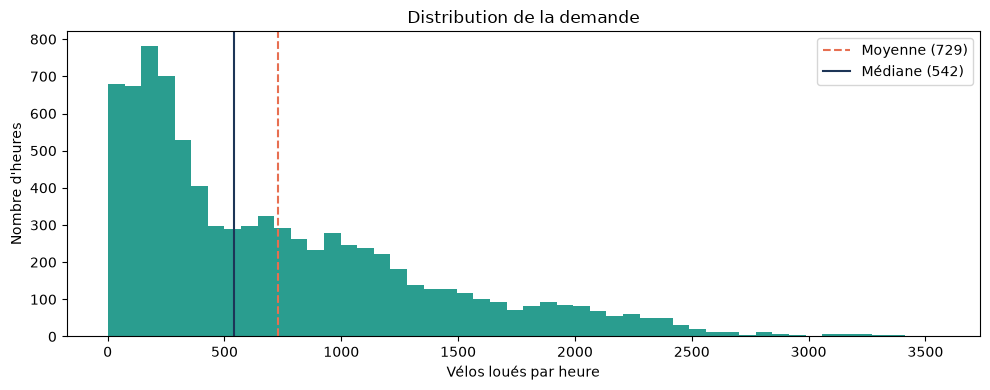

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df[CIBLE], bins=50, color="#2a9d8f")
ax.axvline(df[CIBLE].mean(), color="#e76f51", linestyle="--", label=f"Moyenne ({df[CIBLE].mean():.0f})")
ax.axvline(df[CIBLE].median(), color="#1d3557", label=f"Médiane ({df[CIBLE].median():.0f})")
ax.set(xlabel="Vélos loués par heure", ylabel="Nombre d'heures", title="Distribution de la demande")
ax.legend()
plt.tight_layout()
plt.show()

La demande est **asymétrique** : beaucoup d'heures avec peu de locations (23 % des heures sous 200 vélos), et une longue queue jusqu'à plus de 3 500 vélos/h (moins de 6 % des heures au-dessus de 2 000). La moyenne (729) est donc plus haute que la médiane.

On garde la cible telle quelle dans le preprocessing : si un modèle a besoin de la transformer (par exemple la normaliser pour le réseau de neurones), il le fait dans son propre pipeline.

Demande moyenne : 729 vélos/heure (min 2, max 3556)


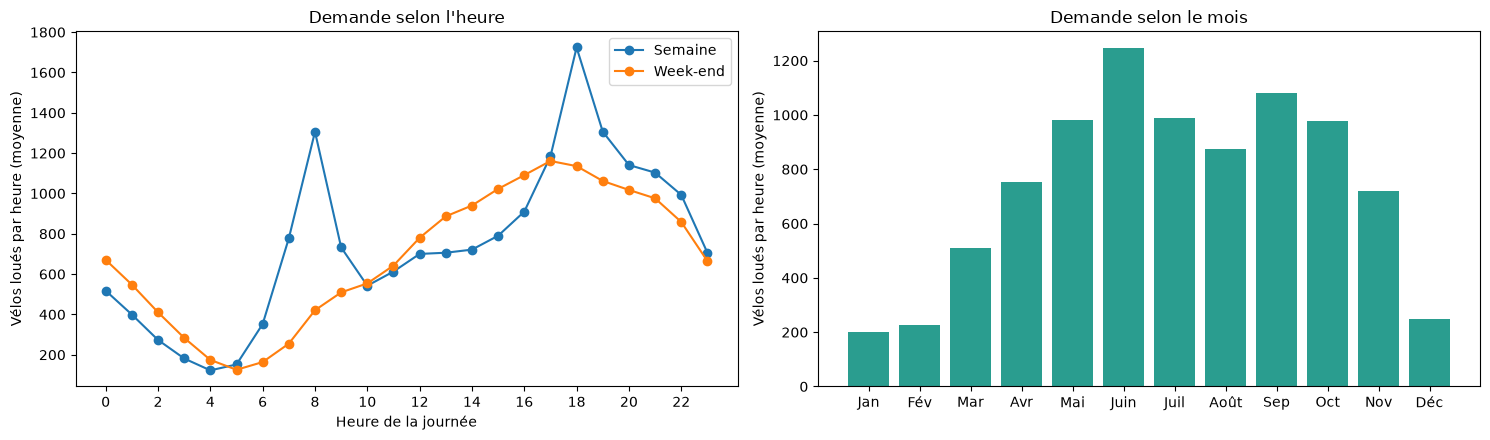

In [9]:
print(f"Demande moyenne : {df[CIBLE].mean():.0f} vélos/heure (min {df[CIBLE].min()}, max {df[CIBLE].max()})")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Demande moyenne selon l'heure de la journée
by_hour = df.groupby(["hour", "is_weekend"])[CIBLE].mean().unstack()
axes[0].plot(by_hour.index, by_hour[0], "o-", label="Semaine")
axes[0].plot(by_hour.index, by_hour[1], "o-", label="Week-end")
axes[0].set(xlabel="Heure de la journée", ylabel="Vélos loués par heure (moyenne)",
            title="Demande selon l'heure", xticks=range(0, 24, 2))
axes[0].legend()

# Demande moyenne selon le mois
month_names = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]
by_month = df.groupby("month")[CIBLE].mean()
axes[1].bar([month_names[m - 1] for m in by_month.index], by_month.values, color="#2a9d8f")
axes[1].set(ylabel="Vélos loués par heure (moyenne)", title="Demande selon le mois")

plt.tight_layout()
plt.show()

La demande dépend surtout de deux choses :
- **selon l'heure** : en semaine, deux pics nets à **8 h** (≈ 1 300 vélos/h) et **18 h** (≈ 1 700), qui correspondent aux trajets domicile-travail. Le week-end, pas de pic : la demande monte doucement jusqu'en fin d'après-midi (≈ 1 150 à 17 h). La nuit, elle tombe à ≈ 120 à 170 vélos/h ;
- **selon le mois** : ≈ 200 à 250 vélos/h en hiver (décembre à février), environ 900 à 1 250 de mai à octobre. La demande est **environ cinq fois plus forte** à la belle saison.

Un bon modèle devra capter ces deux effets : l'heure (avec le type de jour) et la saison (avec la météo).

## 5. Les deux protocoles d'évaluation

Le découpage est le même pour tout le groupe : il est défini dans `decoupage.py`, et les choix sont expliqués en détail dans `decoupage_donnees.ipynb`. Le jeu de test et les plis de cross-validation sont donc identiques pour tous les modèles.

**Protocole daily : généraliser à une journée jamais vue.** Dans chaque mois, 20 % des jours sont tirés au hasard pour le test. Les jours sont gardés entiers : deux heures d'une même journée ne peuvent pas être l'une en train et l'autre en test, sinon le modèle pourrait « recopier » l'heure voisine. Toutes les saisons sont dans le train et dans le test.

**Protocole temporal : généraliser au futur.** On coupe les données dans l'ordre chronologique : les premiers 80 % des jours pour l'entraînement, les derniers 20 % pour le test. Le test est découpé en semaines, et chaque semaine est prédite par un modèle entraîné sur tout ce qui la précède (*walk-forward*), comme le ferait l'opérateur chaque lundi. C'est plus difficile : quand il commence à prédire le test, le modèle n'a vu que les 10 premiers jours de l'automne.

In [10]:
train, test = decoupage_daily(df)
train_temporal, test_temporal = decoupage_temporal(df)

for nom, tr, te in [("DAILY", train, test), ("TEMPORAL", train_temporal, test_temporal)]:
    print(f"[{nom:<8}] Entraînement : {tr['date'].nunique()} jours ({len(tr)} h) | Test : {te['date'].nunique()} jours ({len(te)} h)")

print(f"\nTemporal : entraînement jusqu'au {train_temporal['date'].max():%d/%m/%Y}, "
      f"test du {test_temporal['date'].min():%d/%m/%Y} au {test_temporal['date'].max():%d/%m/%Y} "
      f"({test_temporal['semaine'].nunique()} semaines)")

[DAILY   ] Entraînement : 283 jours (6785 h) | Test : 70 jours (1680 h)
[TEMPORAL] Entraînement : 282 jours (6768 h) | Test : 71 jours (1697 h)

Temporal : entraînement jusqu'au 10/09/2018, test du 11/09/2018 au 30/11/2018 (10 semaines)


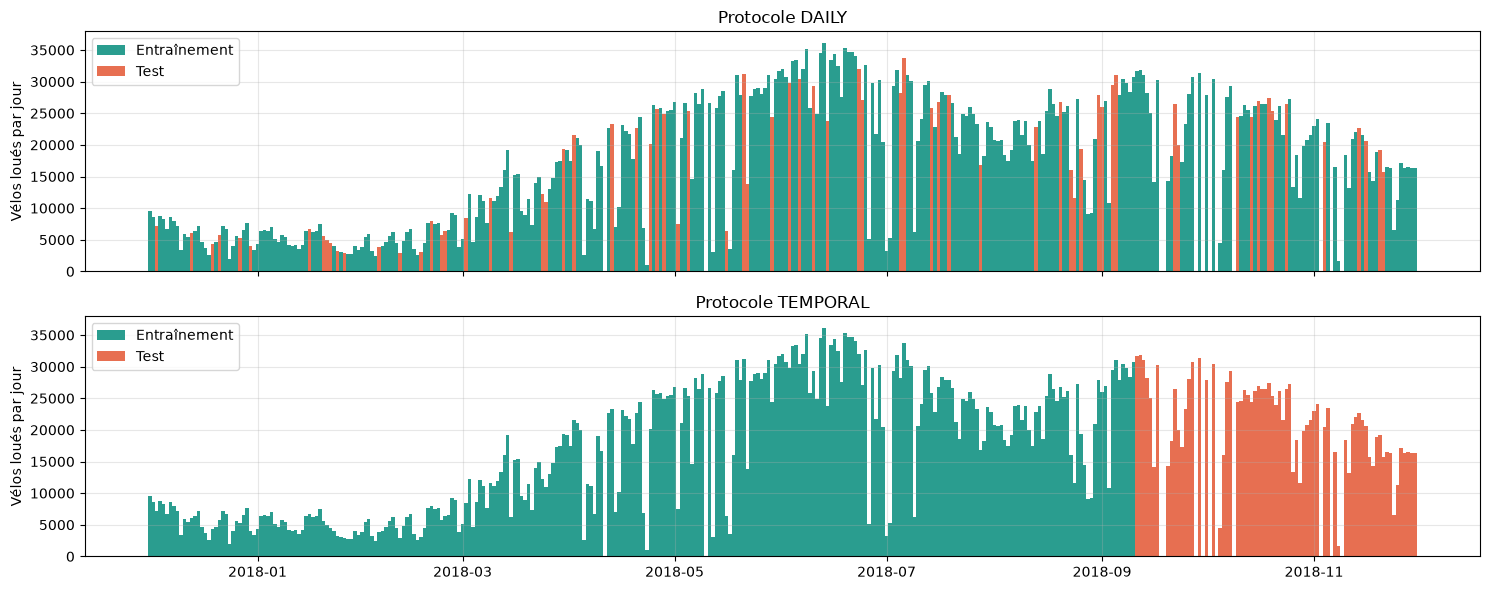

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True, sharey=True)

for ax, nom, te in [(axes[0], "DAILY", test), (axes[1], "TEMPORAL", test_temporal)]:
    par_jour = df.groupby("date")[CIBLE].sum()
    en_test = par_jour.index.isin(te["date"].unique())
    ax.bar(par_jour.index[~en_test], par_jour[~en_test], width=1, color="#2a9d8f", label="Entraînement")
    ax.bar(par_jour.index[en_test], par_jour[en_test], width=1, color="#e76f51", label="Test")
    ax.set(ylabel="Vélos loués par jour", title=f"Protocole {nom}")
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

En daily, les jours de test (en orange) sont répartis sur toute l'année. En temporal, ils forment un seul bloc à la fin : l'automne 2018.

## 6. Méthode d'évaluation

### Les métriques

On mesure l'erreur sur des heures que le modèle n'a jamais vues, avec trois métriques :
- **RMSE** (racine de l'erreur quadratique moyenne) : l'erreur typique en vélos/heure, qui pénalise fortement les grosses erreurs ;
- **MAE** (erreur absolue moyenne) : l'erreur moyenne en vélos/heure ;
- **R²** : la part de la variation de la demande expliquée par le modèle (1 = parfait, 0 = pas mieux que la moyenne, négatif = pire que la moyenne).

La RMSE est la métrique principale pour choisir entre deux modèles.

### Cross-validation et jeu de test

Les réglages (variables, hyperparamètres) sont choisis par **cross-validation sur le train uniquement** :
- **daily** (`cv_daily`, 5 plis) : chaque pli contient des jours entiers, et tous les mois sont représentés dans chaque pli. **Tous les notebooks choisissent leurs réglages avec cette cross-validation.**
- **temporal** (`cv_temporal`) : chaque pli est une semaine du train, prédite avec uniquement les semaines d'avant. Elle sert à vérifier si le modèle choisi tient sur le futur (utilisée dans `regression_lineaire`, `modeles_arbres` et `reseau_neurones`).

Le **jeu de test** n'est utilisé qu'une fois, à la fin, pour mesurer le modèle retenu. 

Tous les modèles sont comparés sur les deux tests (daily et temporal en walk-forward) dans `comparaison_finale.ipynb`, avec les réglages choisis dans chaque notebook.

In [12]:
splits = cv_daily(train)
splits_temporal = cv_temporal(train_temporal)

print(f"DAILY    : {len(splits)} plis")
for i, (tr_idx, va_idx) in enumerate(splits, start=1):
    print(f"  Pli {i} : {train.iloc[tr_idx]['date'].nunique()} jours d'entraînement, {train.iloc[va_idx]['date'].nunique()} jours de validation")

premier, dernier = splits_temporal[0][1], splits_temporal[-1][1]
print(f"\nTEMPORAL : {len(splits_temporal)} plis d'une semaine, "
      f"du {train_temporal.iloc[premier]['date'].min():%d/%m/%Y} au {train_temporal.iloc[dernier]['date'].max():%d/%m/%Y}")

DAILY    : 5 plis
  Pli 1 : 226 jours d'entraînement, 57 jours de validation
  Pli 2 : 227 jours d'entraînement, 56 jours de validation
  Pli 3 : 226 jours d'entraînement, 57 jours de validation
  Pli 4 : 226 jours d'entraînement, 57 jours de validation
  Pli 5 : 227 jours d'entraînement, 56 jours de validation

TEMPORAL : 23 plis d'une semaine, du 01/04/2018 au 10/09/2018


## 7. Les algorithmes testés

Chaque membre du groupe a travaillé sur une famille de modèles, dans son propre notebook, avec les mêmes données et les mêmes protocoles :

| Famille | Modèles | Notebook |
|---|---|---|
| Régression linéaire | régression linéaire, Ridge, Lasso, régression polynomiale | `regression_lineaire.ipynb` |
| Arbres de décision | arbre simple, forêt aléatoire, gradient boosting, XGBoost | `modeles_arbres.ipynb`, `tuning_xgboost.ipynb` |
| Réseau de neurones | perceptron multicouche (`MLPRegressor`) | `reseau_neurones.ipynb` |

- **Régression linéaire** : la demande est une somme pondérée des variables. Simple et interprétable, mais elle ne sait pas représenter seule une courbe en cloche (la demande qui baisse quand il fait trop chaud) ni un effet qui dépend d'une autre variable (le pic de 18 h plus haut en été). On l'enrichit avec de nouvelles variables, des combinaisons de variables et de la régularisation.
- **Arbres de décision** : le modèle découpe les données par des questions successives (« heure ≥ 17 ? », « température < 5 °C ? »). Un seul arbre sur-apprend facilement ; la forêt aléatoire fait la moyenne de nombreux arbres, et le boosting (XGBoost) les construit les uns après les autres pour corriger les erreurs des précédents.
- **Réseau de neurones** : des couches de neurones combinent les variables de façon non linéaire. Il peut apprendre des formes complexes, mais demande plus de réglages (architecture, régularisation, normalisation).

Les meilleurs réglages de chaque famille sont ensuite comparés sur les jeux de test dans `comparaison_finale.ipynb`.

**Ordre de lecture des notebooks :** `introduction` → `decoupage_donnees` → notebooks de modèles → `comparaison_finale`.